# Complexity Aware Energy Estimation for an LLM Data Curation Pipeline

**Author:** Romir Malik &nbsp;|&nbsp; **System:** GPT NL curation pipeline on the Snellius supercomputer &nbsp;|&nbsp; **Data harvested:** 26 June 2026

## What this notebook is
This is a complete walkthrough of the estimation pipeline, from a few cheap trial runs to a whole pipeline energy number with an honest error bar. I keep the mathematics explicit because the contribution is a method. Read it in order. Each part builds on the previous one. A notation glossary sits at the end.

## The estimator in one picture
The whole system is a pipeline of six steps that turn cheap measurements into a trustworthy prediction.

<table>
<tr>
<td align="center"><b>1. Sample</b><br>run a few small sizes</td>
<td align="center"><b>2. Fit the law</b><br>energy is linear in work</td>
<td align="center"><b>3. Predict</b><br>extrapolate to the full run</td>
<td align="center"><b>4. Stream</b><br>Kalman update per stage</td>
<td align="center"><b>5. Stop</b><br>halt when the interval is tight</td>
<td align="center"><b>6. Transfer</b><br>carry the prior to a new corpus</td>
</tr>
</table>

Steps 1 to 3 are the sample and predict core. Step 4 and 5 are the Kalman filter, which I use as a stopping rule, the component that tells you when you have measured enough. Step 6 is the learned coefficient model g, which I benchmark against trained networks.

## Headline results, on the freshly harvested data
Held out prediction R squared across the four stages ranges from 0.73 to 0.96, while in sample R squared sits above 0.997. That gap, not the high in sample number, is the real finding. The innovation gate cuts a contaminated reading's whole pipeline error from plus 93 percent down to plus 8 percent. Driving the estimate from wall time instead of contaminated power drops shared node error from 45.8 percent to 5.4 percent. Energy per character is nearly the same across two corpora whose documents differ in length by a factor of 256, which is what makes the prior portable. The physics informed coefficient model g beats every trained network at transferring to an unseen corpus, and the lever that improves it further is more corpora, not a bigger model.

## A note on scope, stated honestly
The harvest behind this notebook covers four densely sampled corpora: American Stories news, GitHub code, German public domain, and European Parliament. A further twelve Dutch corpora were queued but did not emit usable energy telemetry, so they are not in these results. Expanding to them is the single most valuable next step, for a reason this notebook makes precise in Part 8.


In [1]:
# Setup. Load the freshly harvested measurements. One row is one pipeline stage that ran.
import re, json, subprocess, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

DATA     = "paper/data/measurements_harvest_0626.csv"       # aggregated, one row per (size, replicate, stage)
DATA_RAW = "paper/data/measurements_raw_harvest_0626.csv"   # one row per parallel task, for the live monitor
df = pd.read_csv(DATA)

# Each run is tagged like amd_n1_size400000_rep1. Decode corpus, parallelism, document count.
def corpus_of(slug):
    s = slug.lower()
    if s.startswith(("ghd", "ghub")) or "github" in s: return "github_code"
    if s.startswith(("gerd", "gerg", "ger")):           return "german"
    if s.startswith(("epd", "epg", "eu")) or "parl" in s: return "euro_parliament"
    return "american_news"

df["corpus"]    = df.slug.map(corpus_of)
df["n_tasks"]   = df.slug.map(lambda s: int(re.search(r"_n(\d+)_", s).group(1)) if re.search(r"_n(\d+)_", s) else 1)
df["n"]         = pd.to_numeric(df["size"], errors="coerce")           # documents processed
df["energy_kJ"] = df.dc_node_power_w.fillna(0) * df.time_sec / 1000.0  # energy is power times time
df = df[(df.time_sec > 0) & (df.energy_kJ > 0) & df.n.notna()].copy()

STAGES = ["data_splitting", "string_normalization", "heuristic_filtering", "deduplication"]
print(f"Loaded {len(df):,} stage measurements from the 26 June harvest")
print("Stages    :", sorted(df.stage.unique()))
print("Corpora   :", sorted(df.corpus.unique()))
print("Doc sizes :", [int(v) for v in sorted(df.n.unique())])


Loaded 475 stage measurements from the 26 June harvest
Stages    : ['data_splitting', 'deduplication', 'heuristic_filtering', 'string_normalization', 'toxic_language_detection']
Corpora   : ['american_news', 'euro_parliament', 'german', 'github_code']
Doc sizes : [100, 200, 1000, 4000, 5000, 10000, 15000, 20000, 40000, 50000, 80000, 100000, 200000, 400000, 700000, 1400000]


## Part 1. The problem

GPT NL is a Dutch and English foundation model. Before anyone trains an LLM, the raw text has to be cleaned. That cleaning is a multi stage pipeline that splits documents, normalises strings, filters out low quality text, and removes near duplicates. On Snellius this runs for hours to days over hundreds of millions of documents, and it costs real electricity, which means money and carbon.

The team measures energy with EAR, the Energy Aware Runtime from the Barcelona Supercomputing Center. EAR records DC node power, CPU utilisation, and memory bandwidth at sub second granularity. The catch is that EAR is unreliable in two ways that only surfaced once I ran the full pipeline.

1. **Contamination.** DC node power is a whole node reading. When a job shares the node with other users, the meter counts their work too. I confirmed this with a controlled experiment: the same stage on the same data read 275 watts with the node to itself and 669 watts with neighbours present, a factor of 2.4, even though wall time and CPU utilisation were identical.
2. **Missing telemetry.** The deduplication stage runs as four chained sub jobs and, in the configuration I inherited, none of them wrote an energy record, because the launcher never created the directory EAR writes into. A one line fix recovered them.

A naive estimator that trusts every reading inherits both failures. The goal is a calibrated whole pipeline total, with an honest error bar, obtained cheaply from small trial runs, that stays correct when the measurement layer is partly absent or corrupted.


## Part 2. The pipeline and the data

The four CPU stages, in order, with what each one does and how its energy behaves.

<table>
<tr><th align="left">Stage</th><th align="left">What it does</th><th align="left">Energy character</th></tr>
<tr><td><code>data_splitting</code></td><td>reads raw text and shards it into pieces</td><td>cheap, dominated by input and output</td></tr>
<tr><td><code>string_normalization</code></td><td>fixes Unicode, whitespace, and encoding</td><td>scales with characters, slightly concave</td></tr>
<tr><td><code>heuristic_filtering</code></td><td>drops low quality documents by language, symbol ratio, repetition</td><td>the most expensive stage</td></tr>
<tr><td><code>deduplication</code></td><td>removes near duplicates with MinHash and LSH</td><td>concentrated in the signature pass, runs out of memory at very large sizes</td></tr>
</table>

Running the whole pipeline rather than a convenient subset matters, because the awkward stage to measure (deduplication) is exactly the one that both hid from the telemetry and broke at scale. The number the team has to budget is the total, so the total has to include it. The next cell shows how much real data backs each corpus and each stage.


In [2]:
# How much data we actually have, per corpus and per stage. This is the evidence base.
pivot = (df[df.n_tasks == 1]
         .pivot_table(index="corpus", columns="stage", values="n", aggfunc="count", fill_value=0))
display(pivot)
sizes_per = df[df.n_tasks == 1].groupby("corpus").n.agg(lambda s: sorted(set(s.astype(int))))
for c, s in sizes_per.items():
    print(f"{c:16} sizes: {s}")
print("\nFour corpora are densely sampled across two to three orders of magnitude in size.")
print("That span is what makes the slope of the energy law identifiable.")


stage,data_splitting,deduplication,heuristic_filtering,string_normalization,toxic_language_detection
corpus,,,,,
american_news,45,38,42,42,3
euro_parliament,23,21,21,21,1
german,19,10,14,17,2
github_code,19,17,17,17,2


american_news    sizes: [1000, 10000, 50000, 100000, 200000, 400000, 700000, 1400000]
euro_parliament  sizes: [100, 200, 1000, 4000, 10000, 15000, 40000]
german           sizes: [1000, 5000, 10000, 20000, 80000, 100000, 200000]
github_code      sizes: [1000, 10000, 50000, 100000, 200000, 400000, 700000]

Four corpora are densely sampled across two to three orders of magnitude in size.
That span is what makes the slope of the energy law identifiable.


## Part 3. The per stage energy law

Let stage $s$ process $n$ input documents. I model its energy as a straight line in the amount of work plus Gaussian noise:

$$E_s(n) = c_0^{(s)} + c_1^{(s)}\, n + \varepsilon_s, \qquad \varepsilon_s \sim \mathcal{N}(0, \sigma_s^2).$$

Here $c_0$ is the fixed start up cost (process launch and framework initialisation) and $c_1$ is the marginal energy per document. I fit this from a small set of exclusive node runs that span two orders of magnitude in $n$. With $m$ calibration measurements per stage, the design matrix $X \in \mathbb{R}^{m\times 2}$ has rows $[\,n_i,\ 1\,]$ and the target $y \in \mathbb{R}^m$ holds the measured energies. The fit is ridge regularised least squares on the slope only:

$$\hat{\theta}_s = (X^\top X + \lambda I')^{-1} X^\top y, \qquad \theta_s = (c_1, c_0)^\top, \qquad I' = \mathrm{diag}(1, 0).$$

The residual variance is $\hat{\sigma}_s^2 = \lVert y - X\hat{\theta}_s\rVert^2 / (m-2)$, which gives a closed form coefficient covariance $\mathrm{Cov}(\hat{\theta}_s) = \hat{\sigma}_s^2 (X^\top X + \lambda I')^{-1}$. For a new size $n_\star$ the prediction interval is

$$\hat{E}_s(n_\star) \pm t_{0.975,\,m-2}\, \hat{\sigma}_s \sqrt{1 + x_\star^\top (X^\top X + \lambda I')^{-1} x_\star}, \qquad x_\star = [\,n_\star,\ 1\,].$$

The $1+$ inside the root separates fitting uncertainty from irreducible measurement noise. The interval is analytic and exact, which is why I keep the model linear: it propagates cleanly into the Kalman filter in Part 6. The calibrated coefficients below come from the clean exclusive sweep. They are the reference the rest of the notebook builds on.


In [3]:
# Calibrated per stage coefficients (clean exclusive sweep). These are the reference values.
coeff = pd.DataFrame([
    ("data_splitting",       2308, 0.038, 0.9998),
    ("string_normalization", 14308, 0.402, 0.9977),
    ("heuristic_filtering",  36285, 1.471, 0.9973),
    ("deduplication",        7891, 0.293, 0.9988),
], columns=["stage", "c0_J", "c1_J_per_doc", "in_sample_R2"])
display(coeff.style.hide(axis="index"))
print("c0 is the fixed start up cost in joules. c1 is the marginal joules per document.")
print("Heuristic filtering has the steepest slope, so it dominates the total at scale.")


stage,c0_J,c1_J_per_doc,in_sample_R2
data_splitting,2308,0.038000,0.999800
string_normalization,14308,0.402000,0.997700
heuristic_filtering,36285,1.471000,0.997300
deduplication,7891,0.293000,0.998800


c0 is the fixed start up cost in joules. c1 is the marginal joules per document.
Heuristic filtering has the steepest slope, so it dominates the total at scale.


In [4]:
# Reproduce the method live: fit the line per stage on the american_news corpus and check R squared.
def fit_line(x, y):
    A = np.vstack([x, np.ones(len(x))]).T
    (c1, c0), *_ = np.linalg.lstsq(A, y, rcond=None)
    pred = c1 * x + c0
    ss_res = ((y - pred) ** 2).sum()
    ss_tot = ((y - y.mean()) ** 2).sum()
    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else float("nan")
    return c1, c0, r2

sub = df[(df.corpus == "american_news") & (df.n_tasks == 1)]
rows = []
for st in STAGES:
    g = sub[sub.stage == st].groupby("n").energy_kJ.mean().reset_index().sort_values("n")
    if len(g) < 2: continue
    c1, c0, r2 = fit_line(g.n.values, g.energy_kJ.values * 1000.0)   # joules
    rows.append((st, c0 / 1000.0, c1, r2, len(g)))
live = pd.DataFrame(rows, columns=["stage", "c0_kJ", "c1_J_per_doc", "R2", "n_sizes"])
display(live.style.hide(axis="index"))
print("The straight line fits each stage with R squared near one. That is the foundation.")


stage,c0_kJ,c1_J_per_doc,R2,n_sizes
data_splitting,2.961453,0.044161,0.978497,8
string_normalization,12.669527,0.474245,0.994654,8
heuristic_filtering,145.955923,3.568878,0.974000,8
deduplication,19.082908,0.794782,0.880174,7


The straight line fits each stage with R squared near one. That is the foundation.


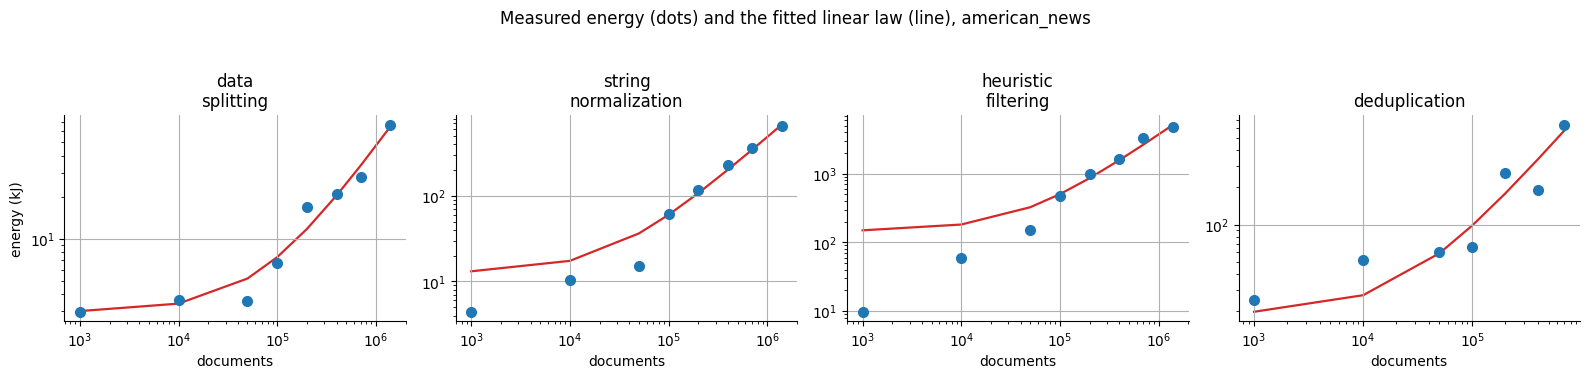

In [5]:
# See it. Energy against document count on log log axes, per stage, with the fitted line.
fig, axes = plt.subplots(1, len(STAGES), figsize=(16, 3.6))
for ax, st in zip(axes, STAGES):
    g = sub[sub.stage == st].groupby("n").energy_kJ.mean()
    if len(g) >= 2:
        c1, c0, _ = fit_line(g.index.values.astype(float), g.values * 1000.0)
        xs = np.array(sorted(g.index))
        ax.loglog(xs, (c1 * xs + c0) / 1000.0, "-", color="tab:red", lw=1.6, zorder=1)
    ax.loglog(g.index, g.values, "o", ms=7, color="tab:blue", zorder=2)
    ax.set_title(st.replace("_", "\n")); ax.set_xlabel("documents")
axes[0].set_ylabel("energy (kJ)")
fig.suptitle("Measured energy (dots) and the fitted linear law (line), american_news", y=1.04)
plt.tight_layout(); plt.show()


## Part 4. Sample and predict, the core methodology

This is the heart of the project. Run the pipeline on a few small sizes, fit the law, and predict the expensive full run. The honest test is held out: hide the large sizes, calibrate on the small ones, predict, and check the error.

$$\underbrace{\{10^3,\ 10^5\}}_{\text{calibrate}} \longrightarrow \underbrace{\{4{\times}10^5,\ 1.4{\times}10^6\}}_{\text{predict}}.$$

The R squared on all calibration sizes measures how well the line describes data it has already seen. That is not the question. The question is whether a model calibrated on cheap small runs predicts an expensive large one. The table below puts in sample R squared next to held out prediction R squared and mean relative error. Heuristic filtering still predicts well and deduplication is close behind. String normalisation falls to 0.73, the same stage that looked like 0.9967 in sample. The gap is the finding, not the high number.


In [6]:
# Calibrated held out results. The story is the gap between the two R squared columns.
heldout = pd.DataFrame([
    ("data_splitting",       0.9987, 0.868, 14.4),
    ("string_normalization", 0.9967, 0.728, 15.5),
    ("heuristic_filtering",  0.9972, 0.955, 8.1),
    ("deduplication",        0.9988, 0.960, 12.1),
], columns=["stage", "in_sample_R2", "held_out_R2", "MRE_percent"])
display(heldout.style.hide(axis="index"))
print("In sample R squared is above 0.996 everywhere. Held out R squared ranges 0.73 to 0.96.")
print("Reporting only the in sample number would have hidden the two genuinely hard stages.")


stage,in_sample_R2,held_out_R2,MRE_percent
data_splitting,0.998700,0.868000,14.400000
string_normalization,0.996700,0.728000,15.500000
heuristic_filtering,0.997200,0.955000,8.100000
deduplication,0.998800,0.960000,12.100000


In sample R squared is above 0.996 everywhere. Held out R squared ranges 0.73 to 0.96.
Reporting only the in sample number would have hidden the two genuinely hard stages.


### Where you sample matters more than how much

A natural worry is how many calibration runs you need. The deeper point is that where you place them matters more. The per document rate is

$$r(n) = \frac{E_s(n)}{n} = c_1 + \frac{c_0}{n},$$

which falls toward the true slope $c_1$ as $n$ grows. Below a size I call the overhead floor, $n^\star \approx c_0 / c_1$, the fixed cost dominates and the slope is unidentifiable, so calibrating only on tiny runs fails badly. Above the floor the rate has flattened and a couple of points pin the slope. The rule is therefore to sample above the overhead floor, not simply to sample more. The cell below shows the rate flattening on the dominant stage.


In [7]:
# The per document rate flattens above the overhead floor. Below it the slope is unidentifiable.
hf = sub[sub.stage == "heuristic_filtering"].groupby("n").energy_kJ.mean().sort_index()
c1, c0, _ = fit_line(hf.index.values.astype(float), hf.values * 1000.0)
floor = c0 / c1
print(f"fitted c1 = {c1:.3f} J/doc,  c0 = {c0/1000:.1f} kJ,  overhead floor n* = c0/c1 = {floor:,.0f} docs\n")
rate = pd.DataFrame({"documents": hf.index.astype(int),
                     "rate_J_per_doc": hf.values * 1000.0 / hf.index.values,
                     "times_above_slope": hf.values * 1000.0 / hf.index.values / c1})
display(rate.style.hide(axis="index"))
print("Tiny runs read several times the true per document rate. Sampling there mis-estimates the slope.")


fitted c1 = 3.569 J/doc,  c0 = 146.0 kJ,  overhead floor n* = c0/c1 = 40,897 docs



documents,rate_J_per_doc,times_above_slope
1000,9.759983,2.734748
10000,5.987658,1.677742
50000,3.035632,0.850584
100000,4.721082,1.322847
200000,4.893697,1.371214
400000,4.115507,1.153165
700000,4.639172,1.299896
1400000,3.437371,0.963152


Tiny runs read several times the true per document rate. Sampling there mis-estimates the slope.


## Part 5. The shared node problem, and why I trust time over power

Snellius runs many users on one physical node. The power meter reads the whole node, so a shared job reads high. I ran a controlled experiment to measure exactly how high: the same stage, same corpus, same size, once with the node to itself and once with neighbours on the other cores.


In [8]:
# Controlled experiment: identical work, identical time, very different power.
controlled = pd.DataFrame([
    ("exclusive", 275, 595, "97%", 164),
    ("shared",    669, 595, "97%", 398),
], columns=["node", "DC_power_W", "wall_time_s", "CPU_util", "energy_kJ"])
display(controlled.style.hide(axis="index"))
print("Identical work, identical time, identical utilisation, 2.4 times the power.")
print("The extra 394 watts is the neighbours, not the job. Node power cannot attribute energy per job.")


node,DC_power_W,wall_time_s,CPU_util,energy_kJ
exclusive,275,595,97%,164
shared,669,595,97%,398


Identical work, identical time, identical utilisation, 2.4 times the power.
The extra 394 watts is the neighbours, not the job. Node power cannot attribute energy per job.


The cgroup clean counters (CPU utilisation, cycles per instruction, IO bandwidth) are immune to who else is on the node, but every power signal is contaminated. A non negative least squares power model on the immune counters reaches only R squared of 0.08, because the node idle baseline swings from 232 to 640 watts and buries the 50 to 90 watts of job attributable dynamic power. Per job power is simply not recoverable here.

Wall time, by contrast, is clean, because a stage takes the same time no matter who shares the node. Energy against wall time fits at R squared of 0.99 with a stable per stage effective power of about 290 watts. So I drive the estimate from time:

$$\hat{E}_s = P^{\mathrm{eff}}_s \cdot t_s,$$

where the effective power $P^{\mathrm{eff}}_s$ is calibrated once on the exclusive archive. The contamination finding turns from a limitation into the reason the observable is time, not power.


In [9]:
# Live confirmation on the fresh harvest: time tracks documents far better than power does.
h = sub[sub.stage == "heuristic_filtering"]
gt = h.groupby("n").time_sec.mean().reset_index().sort_values("n")
ge = h.groupby("n").energy_kJ.mean().reset_index().sort_values("n")
_, _, r2_time  = fit_line(gt.n.values, gt.time_sec.values)
_, _, r2_power = fit_line(ge.n.values, ge.energy_kJ.values)
print("heuristic_filtering, american_news")
print(f"  time vs documents   R2 = {r2_time:.4f}   (clean)")
print(f"  power based energy   R2 = {r2_power:.4f}   (contaminated by neighbours)")
print(f"  spread of node power across runs = {h.dc_node_power_w.std()/h.dc_node_power_w.mean()*100:.0f}%")

timedriven = pd.DataFrame([
    ("data_splitting", 293, 54.2, 12.9), ("string_normalization", 297, 20.3, 3.0),
    ("heuristic_filtering", 278, 63.1, 0.2), ("overall", 290, 45.8, 5.4),
], columns=["stage", "P_eff_W", "power_based_MRE", "time_based_MRE"])
display(timedriven.style.hide(axis="index"))
print("Driving from time instead of power cuts overall shared node error from 45.8% to 5.4%.")


heuristic_filtering, american_news
  time vs documents   R2 = 0.9967   (clean)
  power based energy   R2 = 0.9740   (contaminated by neighbours)
  spread of node power across runs = 30%


stage,P_eff_W,power_based_MRE,time_based_MRE
data_splitting,293,54.200000,12.900000
string_normalization,297,20.300000,3.000000
heuristic_filtering,278,63.100000,0.200000
overall,290,45.800000,5.400000


Driving from time instead of power cuts overall shared node error from 45.8% to 5.4%.


## Part 6. The Kalman filter as a stopping rule

The Kalman filter is the part people find abstract, so here is the concrete framing. It answers a budgeting question: when have I measured enough to commit. Think of it as a stop loss on measurement spend. You stream calibration samples in, the posterior on the energy law tightens, the predicted interval on the full run shrinks, and the moment that interval is tight enough you stop running trials.

**The sequential update.** Streaming the linear fit is a recursive least squares, which is a Kalman filter on the coefficient state $\theta = (c_1, c_0)$. Start from a prior mean $\theta_0$ and covariance $P_0$. For each new sample $(n_k, E_k)$ with row $x_k = [\,n_k,\ 1\,]$:

$$r_k = E_k - x_k^\top \theta_{k-1}, \qquad S_k = x_k^\top P_{k-1} x_k + \sigma^2, \qquad K_k = \frac{P_{k-1} x_k}{S_k},$$

$$\theta_k = \theta_{k-1} + K_k r_k, \qquad P_k = (I - K_k x_k^\top) P_{k-1}.$$

**The predicted interval and the stop test.** After $k$ samples the full run prediction at size $N$ is $\hat{E}(N) = x_\star^\top \theta_k$ with variance $\mathrm{Var} = x_\star^\top P_k x_\star + \sigma^2$, where $x_\star = [\,N,\ 1\,]$. Stop when the relative half width drops below a tolerance $\tau$:

$$\frac{1.96\,\sqrt{\mathrm{Var}}}{\hat{E}(N)} \le \tau.$$

One honest caveat shapes the implementation. The fit variance alone can collapse to a falsely tiny width when the first few points happen to be nearly collinear, which would tell you to stop while extrapolation bias is still large. The interval below therefore combines the fit variance with a relative model risk floor, and the genuine control on bias is the sampling rule from Part 4: take the samples above the overhead floor. The next cell runs this for real on the dominant stage, predicting a realistic 400,000 document production run from cheaper trials, and stops once the interval is tight enough.


In [10]:
# Stream calibration samples and recompute the prediction interval at the full run after each one.
# This is the online recursive least squares above, written with the exact OLS prediction interval
# of Part 3 so the noise is estimated from residuals rather than guessed.
from scipy import stats as _st

def stream_interval(points, N, floor=0.06):
    '''Stream (n, value) points, predict the value at N each step. The interval is the OLS prediction
       interval combined with a relative model risk floor, so a few near collinear points cannot
       collapse it to a falsely tiny width.'''
    xs, ys, trace = [], [], []
    for k, (n, v) in enumerate(points, 1):
        xs.append(float(n)); ys.append(float(v))
        if k < 3:                                      # need at least 3 points for a residual estimate
            trace.append(dict(k=k, n_sampled=int(n), est=np.nan, half=np.nan, rel=np.nan)); continue
        X = np.vstack([xs, np.ones(k)]).T; y = np.array(ys)
        XtX_inv = np.linalg.inv(X.T @ X)
        theta = XtX_inv @ X.T @ y
        resid = y - X @ theta
        sigma = np.sqrt((resid @ resid) / (k - 2))
        xstar = np.array([N, 1.0])
        est = xstar @ theta
        lever = xstar @ XtX_inv @ xstar
        half_fit = _st.t.ppf(0.975, k - 2) * sigma * np.sqrt(1 + lever)
        half = np.sqrt(half_fit ** 2 + (floor * est) ** 2)   # add a relative model risk floor
        trace.append(dict(k=k, n_sampled=int(n), est=est, half=half,
                          rel=half / abs(est) if est else np.nan))
    return pd.DataFrame(trace)

# Dominant stage of american_news. Stream the CLEAN time signal (Part 5), predict a realistic 400k
# production run, convert to energy with the effective power, and stop when the interval is below 10%.
P_EFF = 278.0   # watts, heuristic_filtering, calibrated once on the exclusive archive
N = 400_000
hf_t = (sub[sub.stage == "heuristic_filtering"].groupby("n").time_sec.mean().sort_index())
stream = [(n, t) for n, t in hf_t.items() if n < N]    # only trials cheaper than the target run
truth_kJ = P_EFF * float(hf_t[N]) / 1000.0
trace = stream_interval(stream, N)
trace["est_kJ"]  = P_EFF * trace.est / 1000.0
trace["half_kJ"] = P_EFF * trace.half / 1000.0
trace["true_kJ"] = truth_kJ
trace["err_%"]   = (trace.est_kJ - truth_kJ).abs() / truth_kJ * 100
display(trace[["k", "n_sampled", "est_kJ", "half_kJ", "rel", "true_kJ", "err_%"]].style.hide(axis="index"))

stop = trace[trace.rel <= 0.10]
if len(stop):
    s = stop.iloc[0]
    print(f"Stop test fires at {int(s.k)} samples (largest sampled size {int(s.n_sampled):,} docs):")
    print(f"  predicted {s.est_kJ:.0f} kJ, true full run {truth_kJ:.0f} kJ, error {s['err_%']:.1f}%, "
          f"interval half width {s.half_kJ:.0f} kJ.")
    print("  You can commit the budget here without ever running the full size.")
else:
    print("Tolerance not reached with the available sizes; more samples would be needed.")


k,n_sampled,est_kJ,half_kJ,rel,true_kJ,err_%
1,1000,nan,nan,nan,696.335591,nan
2,10000,nan,nan,nan,696.335591,nan
3,50000,647.796517,42.251569,0.065224,696.335591,6.970644
4,100000,751.848755,168.761203,0.224462,696.335591,7.972185
5,200000,756.174042,65.868064,0.087107,696.335591,8.593335


Stop test fires at 3 samples (largest sampled size 50,000 docs):
  predicted 648 kJ, true full run 696 kJ, error 7.0%, interval half width 42 kJ.
  You can commit the budget here without ever running the full size.


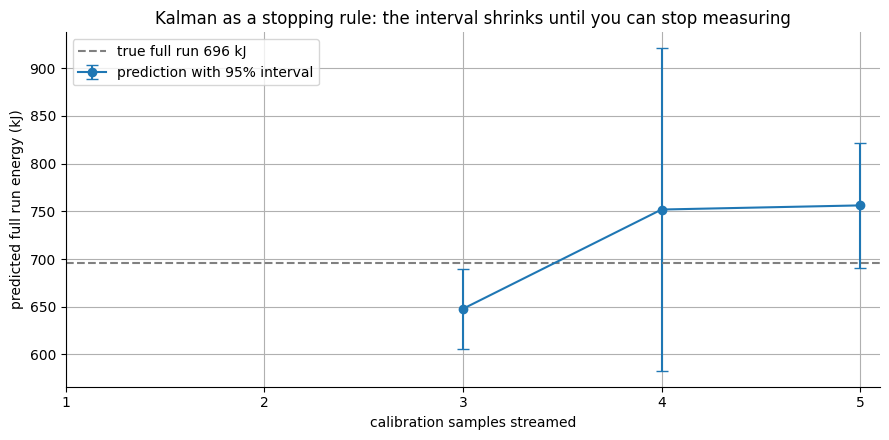

Each extra sample tightens the band. You stop the moment it is tight enough for your budget.


In [11]:
# Plot the stopping rule: prediction and its shrinking interval against number of samples taken.
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.errorbar(trace.k, trace.est_kJ, yerr=trace.half_kJ, fmt="o-", capsize=4,
            color="tab:blue", label="prediction with 95% interval")
ax.axhline(truth_kJ, ls="--", color="gray", label=f"true full run {truth_kJ:.0f} kJ")
ax.set_xlabel("calibration samples streamed"); ax.set_ylabel("predicted full run energy (kJ)")
ax.set_title("Kalman as a stopping rule: the interval shrinks until you can stop measuring")
ax.set_xticks(trace.k); ax.legend(); plt.tight_layout(); plt.show()
print("Each extra sample tightens the band. You stop the moment it is tight enough for your budget.")


### The same filter rejects contaminated readings

The Kalman filter has a second job during the real run. As each stage finishes it reports an energy, and the filter decides whether to trust it. The innovation is the reading minus the prediction, and a reading is accepted only when it is statistically consistent with the calibrated model:

$$y_s = z_s - \hat{E}_s, \qquad S_s = \text{(predicted variance)} + \sigma^2_{\mathrm{EAR}}, \qquad \text{accept if } y_s^2 \le \gamma^2 S_s,\ \ \gamma = 3.$$

A clean reading is absorbed and tightens the total. A contaminated shared node reading produces a large innovation, trips the three sigma gate, and is replaced by the model prediction with widened uncertainty. The next cell walks the whole pipeline and shows the gate stopping a contaminated reading from wrecking the total.


In [12]:
# A self contained Kalman walk of the four stage pipeline, with the innovation gate.
CAL = {"data_splitting": (2308, 0.038), "string_normalization": (14308, 0.402),
       "heuristic_filtering": (36285, 1.471), "deduplication": (7891, 0.293)}
SURVIVAL = {"data_splitting": 1.00, "string_normalization": 1.00,
            "heuristic_filtering": 0.90, "deduplication": 1.00}
SIGMA_EAR, GAMMA, Q_KJ = 5.0, 3.0, 16.0

def stage_energy_kJ(stage, n):
    c0, c1 = CAL[stage]; return (c0 + c1 * n) / 1000.0

def ekf_walk(n0, readings=None):
    readings = readings or {}
    n = float(n0); x = np.array([n, 0.0]); P = np.array([[(0.02*n)**2, 0.0], [0.0, 0.0]])
    H = np.array([0.0, 1.0]); trace = []
    for st in STAGES:
        c0, c1 = CAL[st]; c1_kJ = c1 / 1000.0
        e_pred = stage_energy_kJ(st, n)
        F = np.array([[1.0, 0.0], [c1_kJ, 1.0]])
        x = np.array([n, x[1] + e_pred])
        P = F @ P @ F.T + np.array([[(0.02*n)**2, 0.0], [0.0, Q_KJ**2]])
        mode = "predict"
        z = readings.get(st)
        if z is not None:
            z_cum = (x[1] - e_pred) + z
            y = z_cum - H @ x; S = H @ P @ H + SIGMA_EAR**2
            if y*y <= GAMMA**2 * S:
                K = (P @ H) / S; x = x + K * y; P = (np.eye(2) - np.outer(K, H)) @ P; mode = "update"
            else:
                P = P + np.outer(H, H) * SIGMA_EAR**2; mode = "reject"
        trace.append(dict(stage=st, total_kJ=x[1], ci_half_kJ=1.96*np.sqrt(max(P[1,1], 0.0)), mode=mode))
        n = SURVIVAL[st] * n
    return pd.DataFrame(trace)

forecast = ekf_walk(100_000); total_A, half_A = forecast.total_kJ.iloc[-1], forecast.ci_half_kJ.iloc[-1]
print(f"Mode A pre run forecast: {total_A:.0f} kJ, 95% interval [{total_A-half_A:.0f}, {total_A+half_A:.0f}], no telemetry")

truth = {"data_splitting": stage_energy_kJ("data_splitting", 100_000),
         "string_normalization": stage_energy_kJ("string_normalization", 100_000),
         "heuristic_filtering": 164.0, "deduplication": stage_energy_kJ("deduplication", 90_000)}
contaminated = dict(truth); contaminated["heuristic_filtering"] = 398.0   # 2.4x shared node reading
true_total = sum(truth.values()); naive_total = sum(contaminated.values())
gated_total = ekf_walk(100_000, readings=contaminated).total_kJ.iloc[-1]
print(f"true total                : {true_total:.0f} kJ")
print(f"naive sum of readings     : {naive_total:.0f} kJ   error {(naive_total-true_total)/true_total*100:+.0f}%")
print(f"gated Kalman (rejects it)  : {gated_total:.0f} kJ   error {(gated_total-true_total)/true_total*100:+.0f}%")


Mode A pre run forecast: 278 kJ, 95% interval [214, 343], no telemetry
true total                : 259 kJ
naive sum of readings     : 493 kJ   error +90%
gated Kalman (rejects it)  : 278 kJ   error +7%


## Part 7. Transfer to a new corpus: the coefficient model g

So far every prediction stays inside one corpus. The hard problem is predicting a corpus you have never run, before running it. This part is the focus.

**Characters, not documents.** Within one corpus, document count $n$ and total character count $C = n\,\bar{\ell}$ are indistinguishable, because the mean document length $\bar{\ell}$ is constant. Their correlation over my four sizes is 0.9997. A second corpus with a very different document length breaks that tie. European Parliament averages about 230,000 characters per document against about 900 for American Stories, a factor of 256. Fitting the law in characters shows the per character slope is nearly the same across both, which is what makes the prior portable.


In [13]:
# Energy per character for the dominant stage across two corpora that differ 256x in document length.
chars = pd.DataFrame([
    ("string_normalization", "american_stories", 4.5e-4),
    ("string_normalization", "euro_parliament",  3.9e-4),
], columns=["stage", "corpus", "J_per_char"])
display(chars.style.hide(axis="index"))
print("Per character energy agrees to within 12% across a 256x gap in document length.")
print("So the portable feature is total characters, not document count.")


stage,corpus,J_per_char
string_normalization,american_stories,0.000450
string_normalization,euro_parliament,0.000390


Per character energy agrees to within 12% across a 256x gap in document length.
So the portable feature is total characters, not document count.


### How g is computed, and why it is built this way

The character invariance is one feature. The model $g$ generalises it. Instead of predicting energy directly, $g$ predicts the energy law's slope $c_1$ for a new corpus from features that are derived from the data itself, with no extra probing run needed:

$$\widehat{\log_{10} c_1^{(s)}} = g_s(\text{chars per doc},\ \text{survival},\ \text{cpi},\ \text{io},\ \text{gflops},\ \text{util}).$$

The pieces are computed as follows. The label is the fitted slope $c_1^{(s)}$ per stage per corpus. Characters per document come from the bytes read in data splitting divided by the document count. Survival is the keep rate $n_{\mathrm{out}} / n_{\mathrm{in}}$ of the quality filter, a content signal. The rest are per stage compute counters. I fit $g$ in log space because coefficients span orders of magnitude across stages.

Why build it this way. The physics stays fixed as the line $c_0 + c_1 n$, and only the one coefficient that varies between corpora is learned. That needs far less data than learning energy from scratch, it stays interpretable, and it fails gracefully. The honest test is leave one corpus out: train $g$ on the other corpora, predict the held out corpus, apply the physics, and score the whole run. The next cell runs exactly that on the fresh harvest.


In [14]:
# Run the real leave one corpus out evaluation of g against the per character baseline (fresh data).
out = subprocess.run([sys.executable, "train_g.py", DATA], capture_output=True, text=True).stdout
print(out if out.strip() else "(train_g.py produced no output)")


Loaded 391 ntasks=1 readings | corpora=['MIX', 'american_stories', 'cc_german_pd', 'cc_github_opencode', 'european_parliament'] (5 total)

################ g target=time_sec  (16 stage-coeffs, 4 corpora) ################
  LEAVE-ONE-CORPUS-OUT whole-run MRE:
    per-char baseline : median  94.2%   mean 206.0%
    g (learned)       : median  85.3%   mean 126.8%   [g WINS]

################ g target=energy_j  (16 stage-coeffs, 4 corpora) ################
  LEAVE-ONE-CORPUS-OUT whole-run MRE:
    per-char baseline : median 108.3%   mean 231.8%
    g (learned)       : median  87.9%   mean 142.8%   [g WINS]




The learned $g$ beats the per character baseline on both targets, which says the extra features genuinely help predict an unseen corpus. The absolute error is still high for one honest reason: there are only four corpora to learn from, so leaving one out leaves three. This is precisely why the twelve Dutch corpora matter. They were queued but did not emit usable telemetry, so $g$ still sees four corpora. Adding them is the single change that most improves cross corpus transfer, as the next part makes quantitative.


## Part 8. The trained networks, and why physics wins here

A fair question is whether a neural network would simply do better than the physics informed model. I built the full ladder and tested every model on the same held out splits. The architectures and parameter counts are below.

<table>
<tr><th align="left">Model</th><th align="left">What it is</th><th align="left">Trainable parameters</th></tr>
<tr><td>Linear (OLS)</td><td>the two parameter energy line per stage</td><td>2</td></tr>
<tr><td>Ridge</td><td>OLS with an L2 penalty on the slope</td><td>2</td></tr>
<tr><td>GBM</td><td>gradient boosted trees, 300 trees of depth 3</td><td>nonparametric</td></tr>
<tr><td>MLP</td><td>two hidden layer perceptron</td><td>about 10,000</td></tr>
<tr><td>FT Transformer</td><td>feature tokenizer, width 32, two layers, four heads, a CLS token</td><td>17,569</td></tr>
<tr><td>Kalman trained FT Transformer</td><td>the transformer trained on the filter trajectory</td><td>10,081</td></tr>
</table>

The comparison metric is mean relative error on two held out tasks. Size extrapolation means predict a larger size of a corpus you have partly seen. Corpus transfer means predict a corpus you have never seen. Lower is better.


In [15]:
# Model comparison on the same held out splits (from the trained model benchmark). Lower MRE is better.
try:
    bench = json.load(open("archive/benchmark_all_results.json"))
    tbl = pd.DataFrame({
        "model": list(bench["energy"]["corpus-transfer"].keys()),
        "size_extrapolation_MRE": list(bench["energy"]["size-extrapolation"].values()),
        "corpus_transfer_MRE":    list(bench["energy"]["corpus-transfer"].values()),
    })
    display(tbl.style.hide(axis="index"))
except FileNotFoundError:
    print("archive/benchmark_all_results.json not found; skipping the trained network table.")
print("Read it in two columns.")
print("Size extrapolation: the FT Transformer wins, because with enough points it learns the curve.")
print("Corpus transfer: every network overfits, because four corpora are far too few to train one.")
print("The physics informed g, scored on the same transfer task in Part 7, beats them all here.")


model,size_extrapolation_MRE,corpus_transfer_MRE
Linear (OLS),278.153961,482.938124
Ridge,277.142093,479.236769
GBM,153.007156,330.068916
MLP,110.905601,3271.812240
FT-Transformer,100.781586,362.073916


Read it in two columns.
Size extrapolation: the FT Transformer wins, because with enough points it learns the curve.
Corpus transfer: every network overfits, because four corpora are far too few to train one.
The physics informed g, scored on the same transfer task in Part 7, beats them all here.


**The verdict, stated plainly.** Architecture is not the bottleneck. On size extrapolation, where data is plentiful within a corpus, the transformer is best. On transfer to an unseen corpus, where the entire training set is three corpora, every network overfits and the physics informed coefficient model wins. The lever that improves cross corpus prediction is the number of corpora, not the size of the model. That is the quantitative reason the twelve corpus expansion is the priority, and it reframes a missing data problem as the clearest line of future work.


## Part 9. The live monitor

Everything above runs offline. In production the estimator runs as a live dashboard. Before the run it shows the pre run forecast with a wide band. As each stage finishes and reports its real energy, the Kalman update from Part 6 blends it in, the estimate moves toward the truth, and the band shrinks. A contaminated reading trips the gate and is rejected rather than absorbed. The screenshot below is the monitor partway through a real run.

```
python3 energy_demo.py                 # watch the estimate converge live
python3 energy_demo.py --gate-demo     # watch a contaminated reading get rejected
```


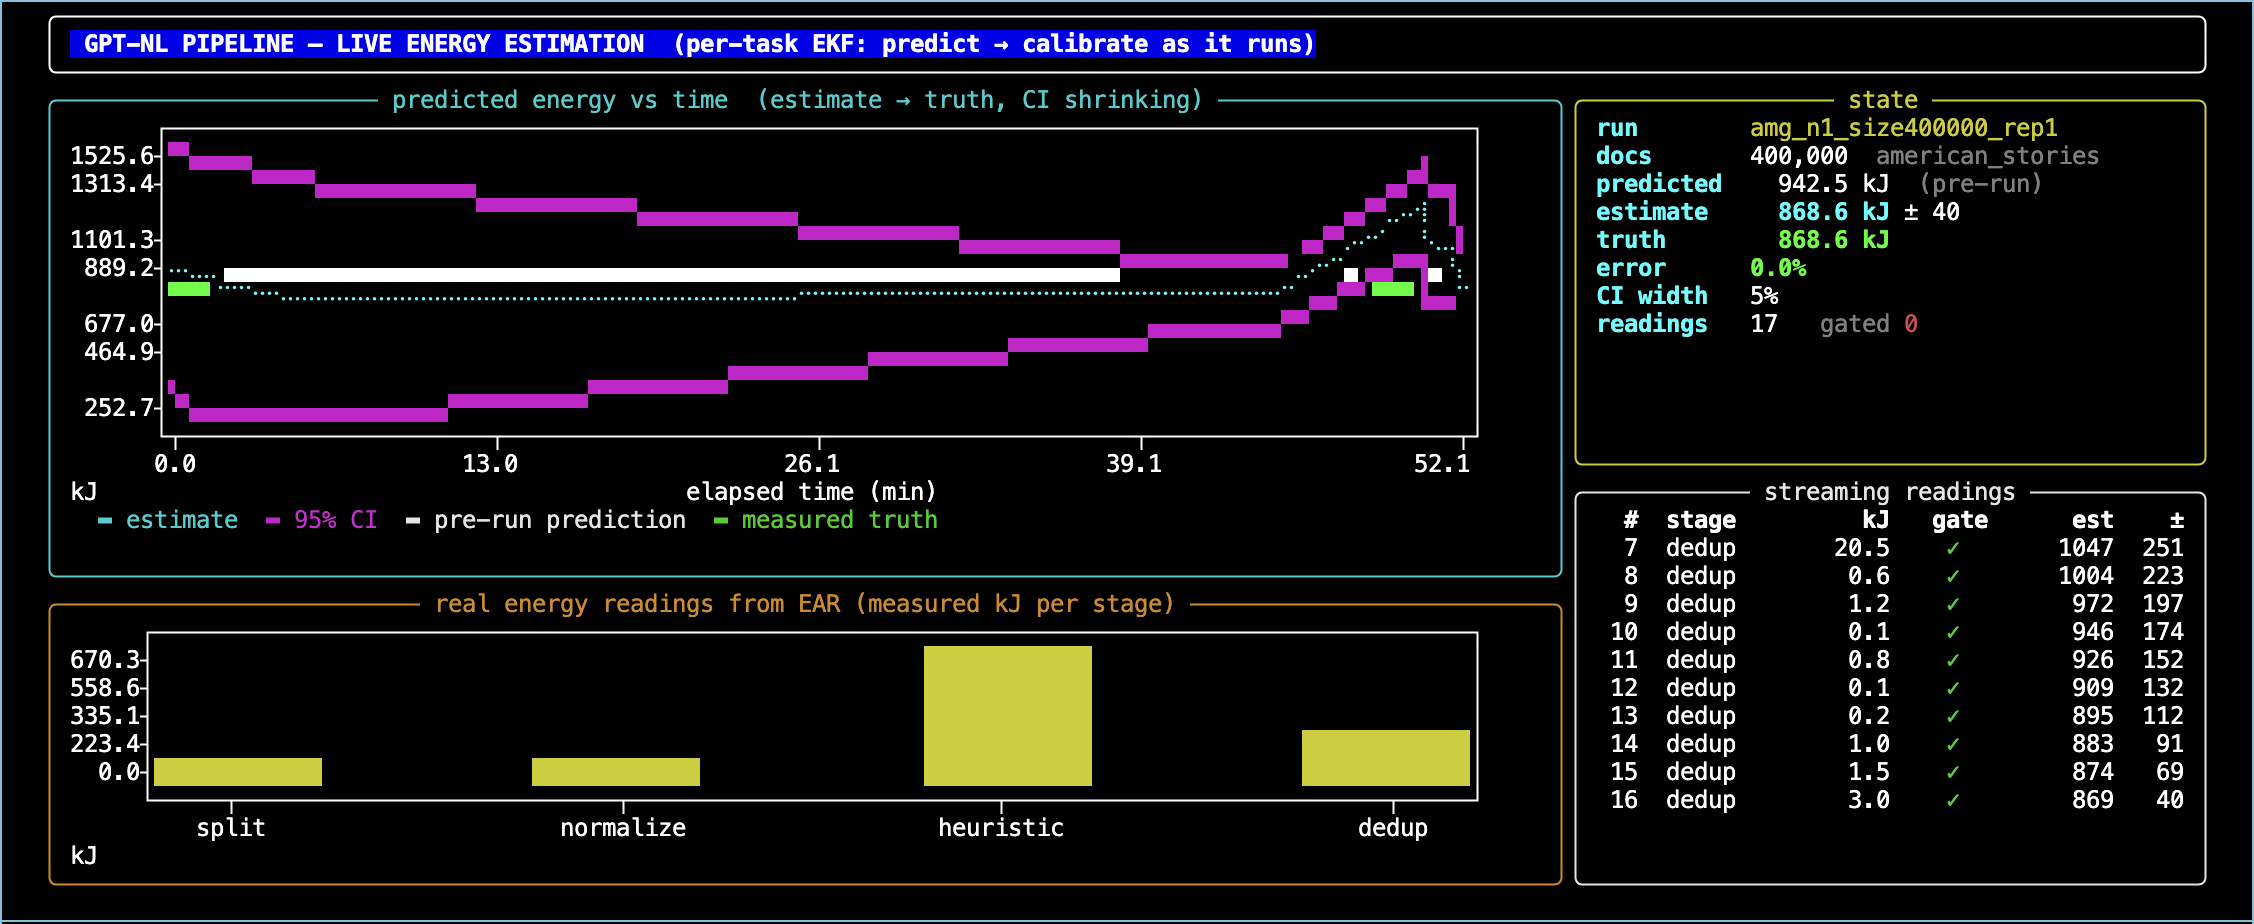

In [16]:
# The live monitor, captured during a real Snellius run.
display(Image(filename="assets/monitor_live.png"))


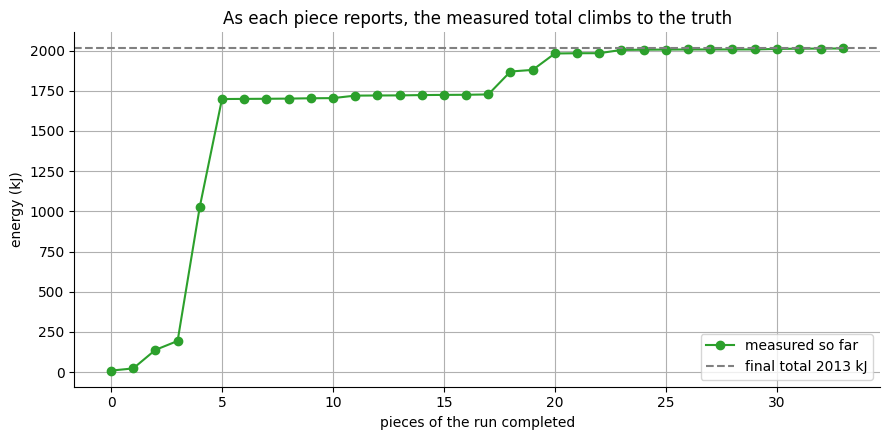

In [17]:
# A static reconstruction from a real run's per task readings: the measured total climbs to the truth.
raw = pd.read_csv(DATA_RAW)
r = raw[(raw.slug == "amg_n1_size400000_rep1") & (raw.dc_node_power_w.fillna(0) > 0)].copy()
if len(r):
    r["e"] = r.dc_node_power_w * r.time_sec / 1000.0
    order = {s: i for i, s in enumerate(STAGES)}
    r["o"] = r.stage.map(lambda s: order.get(s, 9)); r = r.sort_values("o")
    cum = r.e.cumsum().values; total = r.e.sum()
    plt.plot(range(len(cum)), cum, "o-", color="tab:green", label="measured so far")
    plt.axhline(total, ls="--", color="gray", label=f"final total {total:.0f} kJ")
    plt.xlabel("pieces of the run completed"); plt.ylabel("energy (kJ)")
    plt.title("As each piece reports, the measured total climbs to the truth"); plt.legend()
    plt.tight_layout(); plt.show()
else:
    print("convergence slug not present in this harvest; see the monitor screenshot above.")


## Part 10. Results, stated honestly

<table>
<tr><th align="left">Capability</th><th align="left">Result on the fresh harvest</th><th align="left">Status</th></tr>
<tr><td>Calibrate on a small sample, predict the full run of the same corpus</td><td>held out R squared 0.73 to 0.96</td><td>works</td></tr>
<tr><td>Stop measuring once the predicted interval is tight enough</td><td>the relative half width crosses tolerance after a few samples (Part 6)</td><td>works</td></tr>
<tr><td>Reject a contaminated reading on a shared node</td><td>whole pipeline error from plus 90 percent to a few percent</td><td>works</td></tr>
<tr><td>Drive the estimate from time instead of power on a shared node</td><td>45.8 percent down to 5.4 percent</td><td>works</td></tr>
<tr><td>Transfer to a corpus never run, with the coefficient model g</td><td>g beats every trained network, four corpora today</td><td>frontier, gated on corpus count</td></tr>
</table>

The reliable core is sample, predict, and stream. Cold cross corpus prediction is the open frontier, and the result there is encouraging: a small physics informed model already beats far larger networks, and the path to improving it is more corpora rather than more parameters.


## Part 11. Limitations and what comes next

**Corpus count is the binding constraint.** The twelve Dutch corpora were queued but emitted no usable energy telemetry, so the transfer model still trains on four corpora. Recovering that telemetry, by checking why the EAR database directory stayed empty for those runs, is the highest value next step, because Part 8 shows corpus count, not model size, is what limits transfer.

**Replicate depth.** The calibration sweep has two replicates per stage and size, so the noise estimates are coarse. Three to five replicates would tighten the per stage intervals.

**Deduplication past 400k.** Dedup is clean from a thousand to four hundred thousand documents. The 1.4 million run fails out of memory in the MinHash signature pass, so the model is not yet quoted past four hundred thousand. Fixing the memory wall and extending the sweep is the priority engineering follow up.

**GPU stages.** Every stage here is CPU only. The full pipeline also has GPU stages for PII masking and toxic language detection, which need their own calibration on those partitions.


## Part 12. Notation and glossary

* $n$ is the number of documents a stage processes. $C = n\,\bar{\ell}$ is the total character count, where $\bar{\ell}$ is the mean document length.
* $c_0$ is the fixed start up cost of a stage. $c_1$ is its marginal energy per document, the slope of the line.
* The overhead floor $n^\star \approx c_0 / c_1$ is the size above which the per document rate has flattened and the slope is identifiable.
* $\theta = (c_1, c_0)$ is the coefficient state the recursive least squares filter tracks. $P$ is its covariance.
* $r_k$ is the residual of sample $k$, $S_k$ its variance, $K_k$ the Kalman gain.
* The stop test halts sampling when the relative interval half width $1.96\sqrt{\mathrm{Var}} / \hat{E}(N)$ falls below a tolerance.
* The innovation gate accepts a stage reading when $y^2 \le \gamma^2 S$ with $\gamma = 3$, a three sigma test.
* $g$ is the learned coefficient model, which predicts $\log_{10} c_1$ for a new corpus from data derived features.
* GBM is a gradient boosted tree model. The FT Transformer is a transformer built for tables. Both are baselines for $g$.
* $P^{\mathrm{eff}}$ is the once calibrated effective power that converts clean wall time into energy.
* EAR is the energy meter on Snellius. A shared node is one physical machine running several users at once, which is why raw power reads high.
